# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [12]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import platform
import warnings
warnings.filterwarnings('ignore')

# OS별 한글 폰트 설정 (Windows: 맑은 고딕 / Mac: AppleGothic / 그외(Colab 등): 나눔고딕)
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

In [13]:
# 문제 설정
n = 200  # 총 시행 횟수
x = 12   # 관찰된 성공 횟수
p = 0.1  # 귀무가설에서의 성공 확률

print(f"관찰 결과: {n}번 시도 중 {x}번 성공 (관찰 성공률 {x/n:.1%})")

관찰 결과: 200번 시도 중 12번 성공 (관찰 성공률 6.0%)


**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

In [ ]:
# [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 뽑기 확률은 10%다.
# H₁ (대립가설): 뽑기 확률은 10%보다 작다.
# p-값 = P(X ≤ 12 | n=200, p=0.1), 즉 왼쪽 꼬리의 넓이

In [ ]:
# 1. 단측검정(왼쪽 꼬리)을 선택한 이유
#    - 유저들의 의혹은 "확률이 10%와 다르다"가 아니라 "10%보다 낮다"이다.
#    - 그래서 대립가설을 '≠ 0.1'(양측)이 아니라 '< 0.1'(단측, 왼쪽)로 세웠다.
#
# 2. 양측검정과 단측검정의 기각역 차이 (유의수준 α = 0.05)
#    - 양측검정: "다르다"를 검정하므로 너무 작은 쪽과 너무 큰 쪽을 모두 봐야 한다.
#      따라서 α = 0.05를 양쪽 꼬리에 나눠, 왼쪽 꼬리 0.025 + 오른쪽 꼬리 0.025 = 0.05가 되도록
#      임계치를 두 개 잡는다.
#    - 단측검정: "적다"만 검정하면 되므로 오른쪽 꼬리는 볼 필요가 없다.
#      α = 0.05 전부를 왼쪽 꼬리에 두고, 왼쪽 꼬리 넓이가 0.05가 되는 임계치 하나만 잡는다.
#      관측한 통계량이 이 임계치보다 왼쪽(기각역)에 있으면 H₀를 기각한다.
#
# 3. 이 문제에 적용
#    - 이항분포는 이산분포라서 왼쪽 꼬리 넓이가 정확히 0.05가 되지 않으므로,
#      0.05를 넘지 않는 범위까지를 기각역으로 잡는다.
#      P(X ≤ 12) = 0.032 (≤ 0.05),  P(X ≤ 13) = 0.057 (> 0.05)  →  기각역: X ≤ 12
#    - 관측값 12회가 기각역 안에 있다. (p-값 = P(X ≤ 12 | n=200, p=0.1) = 0.032 < 0.05)
#      → H₀ 기각: 실제 뽑기 확률이 10%보다 낮다고 볼 통계적 근거가 있다.
#    - 같은 데이터로 양측검정을 하면 p-값이 0.059 > 0.05가 되어 기각하지 못한다.
#      즉, 대립가설의 방향을 어떻게 세우느냐에 따라 결론이 달라질 수 있다.

단측 기각역: X ≤ 12   (왼쪽 꼬리 넓이 = 0.0320)
양측 기각역: X ≤ 11 또는 X ≥ 30   (왼쪽 0.0168 + 오른쪽 0.0163)


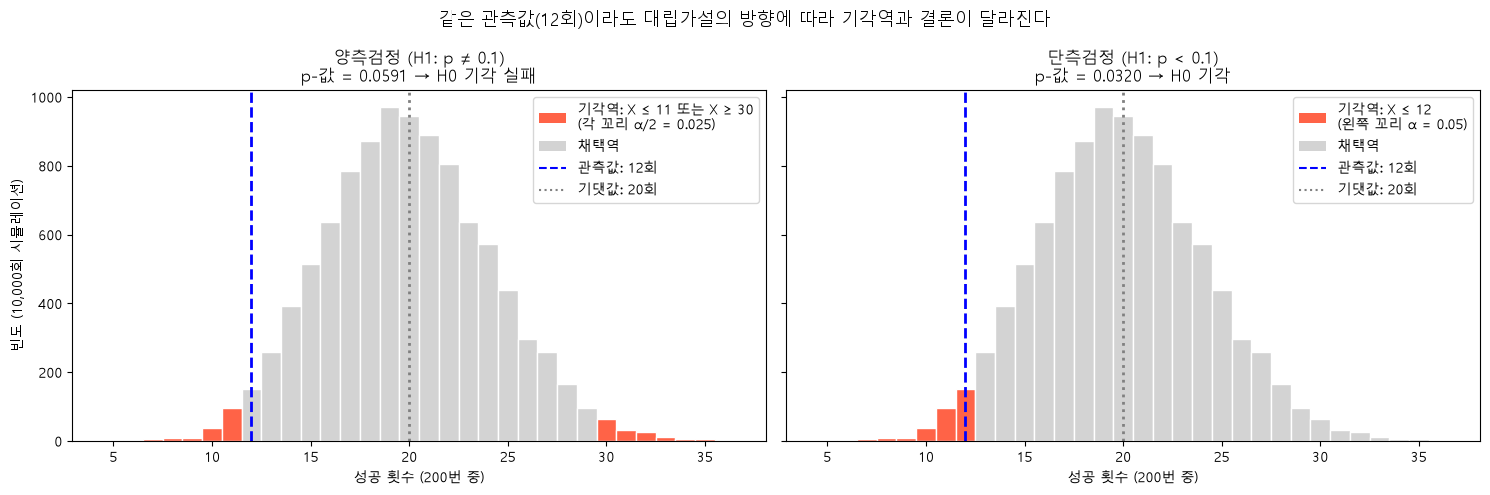

In [14]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

alpha = 0.05
k = np.arange(0, n + 1)
cdf = stats.binom.cdf(k, n, p)        # P(X ≤ k)
sf  = stats.binom.sf(k - 1, n, p)     # P(X ≥ k)

# 임계치 계산 (이산분포라서 꼬리 넓이가 α를 넘지 않는 가장 바깥쪽 값)
crit_one     = k[cdf <= alpha].max()        # 단측: 왼쪽 꼬리 0.05
crit_two_low = k[cdf <= alpha / 2].max()    # 양측: 왼쪽 꼬리 0.025
crit_two_up  = k[sf  <= alpha / 2].min()    # 양측: 오른쪽 꼬리 0.025

p_one = stats.binomtest(x, n, p, alternative='less').pvalue
p_two = stats.binomtest(x, n, p, alternative='two-sided').pvalue

print(f"단측 기각역: X ≤ {crit_one}   (왼쪽 꼬리 넓이 = {stats.binom.cdf(crit_one, n, p):.4f})")
print(f"양측 기각역: X ≤ {crit_two_low} 또는 X ≥ {crit_two_up}"
      f"   (왼쪽 {stats.binom.cdf(crit_two_low, n, p):.4f} + 오른쪽 {stats.binom.sf(crit_two_up - 1, n, p):.4f})")

bins = np.arange(sim_successes.min() - 0.5, sim_successes.max() + 1.5, 1)
centers = (bins[:-1] + bins[1:]) / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
settings = [
    ("양측검정 (H1: p ≠ 0.1)", lambda c: (c <= crit_two_low) | (c >= crit_two_up),
     f"기각역: X ≤ {crit_two_low} 또는 X ≥ {crit_two_up}\n(각 꼬리 α/2 = 0.025)", p_two),
    ("단측검정 (H1: p < 0.1)", lambda c: c <= crit_one,
     f"기각역: X ≤ {crit_one}\n(왼쪽 꼬리 α = 0.05)", p_one),
]

for ax, (title, is_reject, reject_label, p_val) in zip(axes, settings):
    _, _, patches = ax.hist(sim_successes, bins=bins, color='lightgray', edgecolor='white')
    for patch, c in zip(patches, centers):
        if is_reject(c):
            patch.set_facecolor('tomato')   # 기각역 막대 색칠

    ax.axvline(x, color='blue', linestyle='--', linewidth=2)
    ax.axvline(n * p, color='gray', linestyle=':', linewidth=2)

    result = "H0 기각" if p_val < alpha else "H0 기각 실패"
    ax.set_title(f"{title}\np-값 = {p_val:.4f} → {result}")
    ax.set_xlabel("성공 횟수 (200번 중)")
    ax.legend(handles=[
        Patch(facecolor='tomato', label=reject_label),
        Patch(facecolor='lightgray', label='채택역'),
        Line2D([0], [0], color='blue', linestyle='--', label=f'관측값: {x}회'),
        Line2D([0], [0], color='gray', linestyle=':', label=f'기댓값: {n*p:.0f}회'),
    ], loc='upper right')

axes[0].set_ylabel("빈도 (10,000회 시뮬레이션)")
fig.suptitle("같은 관측값(12회)이라도 대립가설의 방향에 따라 기각역과 결론이 달라진다", fontsize=13)
plt.tight_layout()
plt.show()

In [8]:
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?

result = stats.binomtest(x, n, p, alternative='less')   # 왼쪽 꼬리
p_value = result.pvalue
print(f"단측(왼쪽) p-값: {p_value:.4f}")                 # 0.0320
print(f"검산 binom.cdf: {stats.binom.cdf(x, n, p):.4f}") # 같은 값

단측(왼쪽) p-값: 0.0320
검산 binom.cdf: 0.0320


In [9]:
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.

alpha = 0.05
if p_value < alpha:
    print("H₀ 기각: 실제 확률이 10%보다 낮다고 볼 근거가 있다")
else:
    print("H₀ 기각 실패")

H₀ 기각: 실제 확률이 10%보다 낮다고 볼 근거가 있다


In [10]:
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# 힌트: numpy의 이항분포 랜덤 함수(np.random.binomial)를 사용해보세요.

np.random.seed(42)
n_sim = 10000

# "확률 10%로 200번 뽑기"를 10,000번 반복 → 각 회차의 성공 횟수
sim_successes = np.random.binomial(n=n, p=p, size=n_sim)

print(f"시뮬레이션 평균 성공 횟수: {sim_successes.mean():.2f}회 (이론값 n*p = {n*p:.0f}회)")
print(f"시뮬레이션 표준편차: {sim_successes.std():.2f} (이론값 √(np(1-p)) = {np.sqrt(n*p*(1-p)):.2f})")

# 단측(왼쪽 꼬리) 시뮬레이션 p-값: 관찰값 12회 '이하'가 나온 비율
sim_p_value = np.mean(sim_successes <= x)
print(f"\n{x}회 이하로 성공한 비율 (시뮬레이션 p-값): {sim_p_value:.4f}")
print(f"이항검정 정확한 p-값 (binom.cdf):        {stats.binom.cdf(x, n, p):.4f}")

시뮬레이션 평균 성공 횟수: 19.91회 (이론값 n*p = 20회)
시뮬레이션 표준편차: 4.21 (이론값 √(np(1-p)) = 4.24)

12회 이하로 성공한 비율 (시뮬레이션 p-값): 0.0313
이항검정 정확한 p-값 (binom.cdf):        0.0320


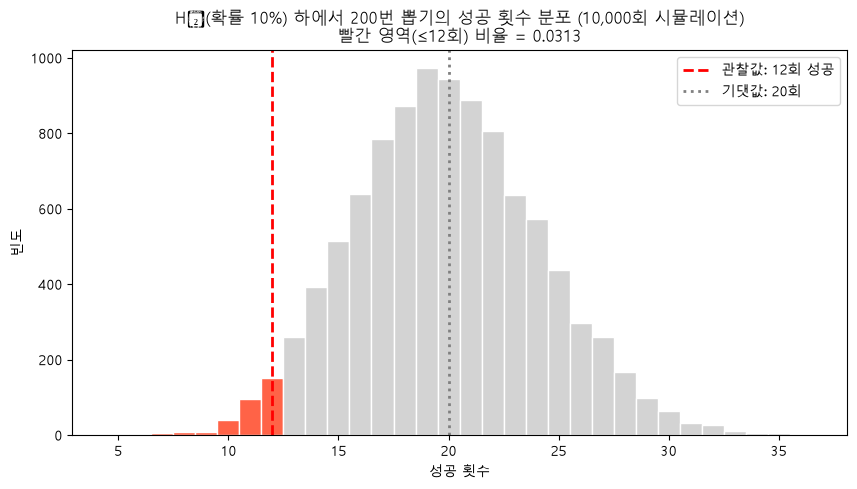

In [11]:
# [문제 1] Q5. 시뮬레이션 결과를 히스토그램으로 그려봅시다.
# 실제 관찰값(12번 성공)을 세로선으로 함께 표시해 봅시다.

plt.figure(figsize=(10, 5))

# 정수값마다 막대 하나가 되도록 bins를 0.5 단위 경계로 설정
bins = np.arange(sim_successes.min() - 0.5, sim_successes.max() + 1.5, 1)
counts, edges, patches = plt.hist(sim_successes, bins=bins, color='lightgray', edgecolor='white')

# 왼쪽 꼬리(12회 이하) 막대 색칠 → 이 넓이가 p-값
for patch, left_edge in zip(patches, edges[:-1]):
    if left_edge + 0.5 <= x:
        patch.set_facecolor('tomato')

plt.axvline(x=x, color='red', linestyle='--', linewidth=2, label=f'관찰값: {x}회 성공')
plt.axvline(x=n * p, color='gray', linestyle=':', linewidth=2, label=f'기댓값: {n*p:.0f}회')

plt.title(f"H₀(확률 10%) 하에서 200번 뽑기의 성공 횟수 분포 (10,000회 시뮬레이션)\n"
          f"빨간 영역(≤{x}회) 비율 = {sim_p_value:.4f}")
plt.xlabel("성공 횟수")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?

In [ ]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 1. p-값(0.032)은 시뮬레이션 히스토그램에서 관측값 12회 '이하'인 왼쪽 꼬리의 넓이다.
#    확률이 정말 10%라면, 지금처럼 12회 이하로 나올 확률이 약 3.2%라는 뜻이다.
#
# 2. 드문 일이다. 10,000번 중 약 300번(3%)만 12회 이하가 나왔고,
#    대부분은 기댓값 20회 근처에 몰려 있다.
#
# 3. "개발사 말이 맞다고 치고 수만 번 돌려봤더니, 우리가 겪은 결과는 거의 안 나오더라.
#    이렇게 드문 일이 우연히 일어났다고 보기보다는, 애초에 개발사 말이 틀렸다고 보는 게 합리적이다."
#    그 '거의 안 나온다'의 기준선이 유의수준 5%다.
#
# 4. p-값이 훨씬 작아진다. (1,000번 중 60회 → p ≈ 0.000004)
#    표본이 커질수록 성공 횟수의 분포가 기댓값 주변으로 좁게 모여서,
#    같은 6%라도 우연으로 설명하기가 훨씬 어려워지기 때문이다.


# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

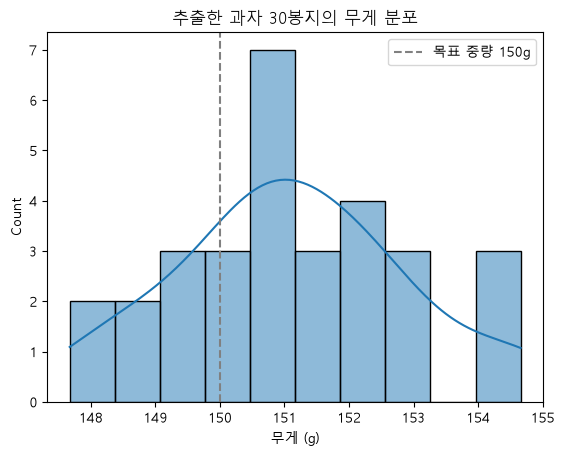

In [15]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [ ]:
# [문제 2] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 과자의 평균 무게는 150g이다.
# H₁ (대립가설): 과자의 평균 무게는 150g이 아니다.

In [16]:
# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.

sample_mean = sample_weights.mean()
sample_std = sample_weights.std(ddof=1)   # 표본표준편차 (n-1로 나눔)

t_stat, p_value = stats.ttest_1samp(sample_weights, popmean=pop_mean)  # 기본값: 양측검정

print(f"표본 평균: {sample_mean:.2f}g, 표본 표준편차: {sample_std:.2f}g")
print(f"t-통계량: {t_stat:.4f}")
print(f"p-값: {p_value:.4f}")

표본 평균: 151.12g, 표본 표준편차: 1.80g
t-통계량: 3.4193
p-값: 0.0019


In [17]:
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
alpha = 0.05

# 양측검정 임계치: 양쪽 꼬리에 α/2 = 0.025씩
df = len(sample_weights) - 1
t_crit = stats.t.ppf(1 - alpha / 2, df)
print(f"임계치: ±{t_crit:.4f} (자유도 {df})")

# 결론 내리기
if p_value < alpha:
    print(f"p-값 {p_value:.4f} < {alpha} → H0 기각")
    print(f"|t| = {abs(t_stat):.4f} > {t_crit:.4f} 이므로 기각역에 있다.")
    print("결론: 과자의 평균 중량이 목표치 150g과 다르다고 볼 통계적 근거가 있다.")
else:
    print(f"p-값 {p_value:.4f} ≥ {alpha} → H0 기각 실패")
    print("결론: 과자의 평균 중량이 150g과 다르다고 볼 근거가 부족하다.")

임계치: ±2.0452 (자유도 29)
p-값 0.0019 < 0.05 → H0 기각
|t| = 3.4193 > 2.0452 이므로 기각역에 있다.
결론: 과자의 평균 중량이 목표치 150g과 다르다고 볼 통계적 근거가 있다.


In [18]:
# [문제 2] Q4. H₀가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장해봅시다.
# 힌트: 표준편차는 우리가 가진 표본의 표준편차를 사용한다고 가정하고, for 반복문을 사용해보세요.

np.random.seed(0)
n_sim = 10000
n_sample = len(sample_weights)   # 30

sim_means = []
for _ in range(n_sim):
    # H0 모집단: 평균 150g, 표준편차는 우리 표본의 표준편차 사용
    fake_sample = np.random.normal(loc=pop_mean, scale=sample_std, size=n_sample)
    sim_means.append(fake_sample.mean())

sim_means = np.array(sim_means)

print(f"시뮬레이션 표본평균들의 평균: {sim_means.mean():.3f}g (H0 평균 {pop_mean}g)")
print(f"시뮬레이션 표본평균들의 표준편차: {sim_means.std():.3f}g "
      f"(이론적 표준오차 σ/√n = {sample_std / np.sqrt(n_sample):.3f}g)")

# 양측 시뮬레이션 p-값: 150g에서 관측값만큼 '또는 그 이상' 떨어진 표본평균의 비율 (양쪽 모두)
obs_diff = abs(sample_mean - pop_mean)
sim_p_value = np.mean(np.abs(sim_means - pop_mean) >= obs_diff)
print(f"\n관측 표본평균: {sample_mean:.3f}g (150g에서 {obs_diff:.3f}g 차이)")
print(f"시뮬레이션 양측 p-값: {sim_p_value:.4f}")

시뮬레이션 표본평균들의 평균: 150.003g (H0 평균 150g)
시뮬레이션 표본평균들의 표준편차: 0.327g (이론적 표준오차 σ/√n = 0.329g)

관측 표본평균: 151.124g (150g에서 1.124g 차이)
시뮬레이션 양측 p-값: 0.0003


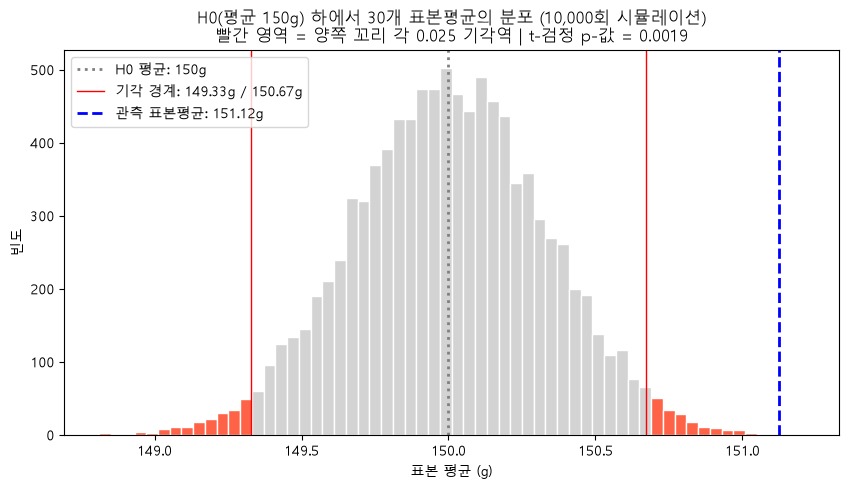

In [19]:
# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.

# 양측검정 기각 경계 (표본평균 단위로 환산): 150 ± t임계치 × 표준오차
se = sample_std / np.sqrt(n_sample)
crit_low, crit_up = pop_mean - t_crit * se, pop_mean + t_crit * se

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hist(sim_means, bins=60, color='lightgray', edgecolor='white')

# 양쪽 꼬리(기각역) 막대 색칠
for patch, left, right in zip(patches, edges[:-1], edges[1:]):
    center = (left + right) / 2
    if center <= crit_low or center >= crit_up:
        patch.set_facecolor('tomato')

plt.axvline(pop_mean, color='gray', linestyle=':', linewidth=2, label=f'H0 평균: {pop_mean}g')
plt.axvline(crit_low, color='red', linestyle='-', linewidth=1,
            label=f'기각 경계: {crit_low:.2f}g / {crit_up:.2f}g')
plt.axvline(crit_up, color='red', linestyle='-', linewidth=1)
plt.axvline(sample_mean, color='blue', linestyle='--', linewidth=2,
            label=f'관측 표본평균: {sample_mean:.2f}g')

plt.title(f"H0(평균 150g) 하에서 30개 표본평균의 분포 (10,000회 시뮬레이션)\n"
          f"빨간 영역 = 양쪽 꼬리 각 0.025 기각역 | t-검정 p-값 = {p_value:.4f}")
plt.xlabel("표본 평균 (g)")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)

- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)

In [ ]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 1. H0(평균 150g)가 사실일 때 30개짜리 표본평균이 어떻게 분포하는지(표본평균의 표본분포)를 나타낸다.
#    중심극한정리에 따라 표본평균은 표본 크기가 충분하면 모집단 분포와 관계없이
#    평균 μ, 표준오차 σ/√n(≈0.33g)인 정규분포에 가까워지기 때문이다.
#
# 2. 흔하지 않다. 관측 표본평균 151.12g은 기각 경계(150.67g)보다 훨씬 오른쪽 꼬리 끝에 있다.
#    p-값(0.0019)은 이 세로선보다 바깥쪽(150g에서 더 멀리 떨어진 양쪽 꼬리)의 넓이로,
#    세로선이 중심에서 멀수록 p-값이 작아진다.
#
# 3. 지금(p=0.0019)보다 조금 더 바깥쪽, 즉 오른쪽 꼬리 끝에 더 가까이 위치할 것이다.
#    (양측이므로 150g보다 가벼운 쪽이었다면 왼쪽 꼬리 끝)
#
# 4. 평균 중량이 목표보다 약 1.1g 무겁게 생산되고 있으므로 충전량 설정을 점검·조정해야 한다.
#    무겁게 나오면 소비자 불만은 없지만, 봉지마다 원재료가 더 들어가 원가 손실이 누적된다.
#    (1.1g × 대량 생산량이면 손실이 상당하다)

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

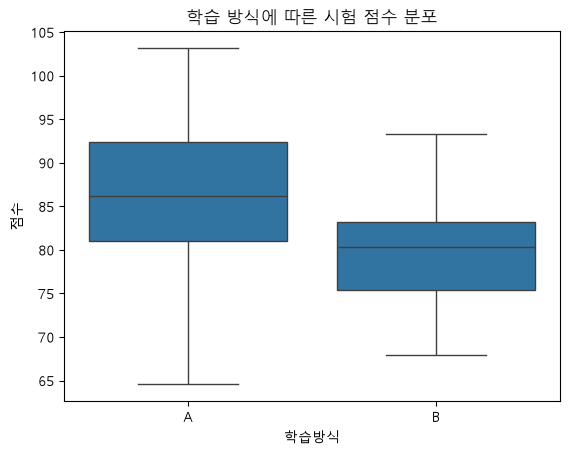

In [20]:
# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

df_scores = pd.DataFrame({'점수': np.concatenate([group_a_scores, group_b_scores]),
                          '학습방식': ['A']*50 + ['B']*50})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x='학습방식', y='점수', data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

In [21]:
# [문제 3] Q1. 두 그룹에 대해 각각 정규성 검정(Shapiro-Wilk test)을 수행하고 p-값을 출력해봅시다.
# H₀: 데이터는 정규분포를 따른다.

alpha = 0.05

for name, scores in [('A', group_a_scores), ('B', group_b_scores)]:
    stat, p_val = stats.shapiro(scores)
    result = "정규성 만족 (H0 기각 실패)" if p_val >= alpha else "정규성 위배 (H0 기각)"
    print(f"그룹 {name}: W = {stat:.4f}, p-값 = {p_val:.4f} → {result}")

그룹 A: W = 0.9876, p-값 = 0.8766 → 정규성 만족 (H0 기각 실패)
그룹 B: W = 0.9866, p-값 = 0.8366 → 정규성 만족 (H0 기각 실패)


In [22]:
# [문제 3] Q2. 두 그룹에 대해 등분산성 검정(Levene's test)을 수행하고 p-값을 출력해봅시다.
# H₀: 두 그룹의 분산은 같다.

print(f"그룹 A 표준편차: {group_a_scores.std(ddof=1):.2f}, 그룹 B 표준편차: {group_b_scores.std(ddof=1):.2f}")

levene_stat, levene_p = stats.levene(group_a_scores, group_b_scores)
print(f"Levene 통계량 = {levene_stat:.4f}, p-값 = {levene_p:.4f}")

if levene_p >= alpha:
    equal_var = True
    print("→ 등분산성 만족 (H0 기각 실패): equal_var=True (Student's t-검정)")
else:
    equal_var = False
    print("→ 등분산성 위배 (H0 기각): equal_var=False (Welch's t-검정)")

그룹 A 표준편차: 9.10, 그룹 B 표준편차: 6.13
Levene 통계량 = 6.1330, p-값 = 0.0150
→ 등분산성 위배 (H0 기각): equal_var=False (Welch's t-검정)


In [23]:
# [문제 3] Q3. 이표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
# 등분산성 가정을 만족했는지 여부에 따라 equal_var 인수를 설정해보세요.

mean_a, mean_b = group_a_scores.mean(), group_b_scores.mean()
obs_diff = mean_a - mean_b
print(f"그룹 A 평균: {mean_a:.2f}점, 그룹 B 평균: {mean_b:.2f}점 (차이: {obs_diff:.2f}점)")

# Q2 결과에 따라 equal_var=False → Welch's t-검정 (양측)
t_stat, p_value = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)
print(f"t-통계량 = {t_stat:.4f}, p-값 = {p_value:.6f}")

if p_value < alpha:
    print("→ H0 기각: 두 학습 방식의 평균 점수에 통계적으로 유의미한 차이가 있다.")
else:
    print("→ H0 기각 실패: 두 학습 방식의 평균 점수 차이가 유의미하다고 보기 어렵다.")

그룹 A 평균: 86.12점, 그룹 B 평균: 79.85점 (차이: 6.27점)
t-통계량 = 4.0426, p-값 = 0.000115
→ H0 기각: 두 학습 방식의 평균 점수에 통계적으로 유의미한 차이가 있다.


In [24]:
# [문제 3] Q4. H₀가 사실(두 그룹의 평균이 같다)이라고 가정하고 시뮬레이션을 10,000번 수행해봅시다.
# 두 그룹의 데이터를 모두 합친 뒤(np.concatenate), 매 반복마다 비복원추출로 50개(가상 A그룹)와
# 나머지 50개(가상 B그룹)로 나누어 두 그룹의 평균 차이를 계산하고 리스트에 저장해보세요.
# 힌트: np.random.permutation 을 사용해보세요.

np.random.seed(1)
n_sim = 10000
n_a = len(group_a_scores)   # 50

# H0: 학습 방식은 점수와 무관 → A/B 라벨을 떼고 100명을 한 집단으로 합침
pooled = np.concatenate([group_a_scores, group_b_scores])

sim_diffs = []
for _ in range(n_sim):
    shuffled = np.random.permutation(pooled)          # 100명을 무작위로 섞기 (비복원)
    fake_a, fake_b = shuffled[:n_a], shuffled[n_a:]   # 앞 50명 = 가상 A, 뒤 50명 = 가상 B
    sim_diffs.append(fake_a.mean() - fake_b.mean())

sim_diffs = np.array(sim_diffs)

print(f"시뮬레이션 평균 차이의 평균: {sim_diffs.mean():.3f}점 (H0이면 0 근처)")
print(f"시뮬레이션 평균 차이의 범위: {sim_diffs.min():.2f} ~ {sim_diffs.max():.2f}점")
print(f"관측 평균 차이 (A - B): {obs_diff:.2f}점")

# 양측 시뮬레이션 p-값: 관측 차이만큼 '또는 그 이상' 벌어진 경우의 비율 (양쪽 모두)
n_extreme = np.sum(np.abs(sim_diffs) >= abs(obs_diff))
sim_p_value = n_extreme / n_sim
if n_extreme == 0:
    print(f"시뮬레이션 p-값: < {1/n_sim} ({n_sim:,}번 중 한 번도 나오지 않음)")
else:
    print(f"시뮬레이션 p-값: {sim_p_value:.4f}")

시뮬레이션 평균 차이의 평균: 0.005점 (H0이면 0 근처)
시뮬레이션 평균 차이의 범위: -5.73 ~ 5.36점
관측 평균 차이 (A - B): 6.27점
시뮬레이션 p-값: < 0.0001 (10,000번 중 한 번도 나오지 않음)


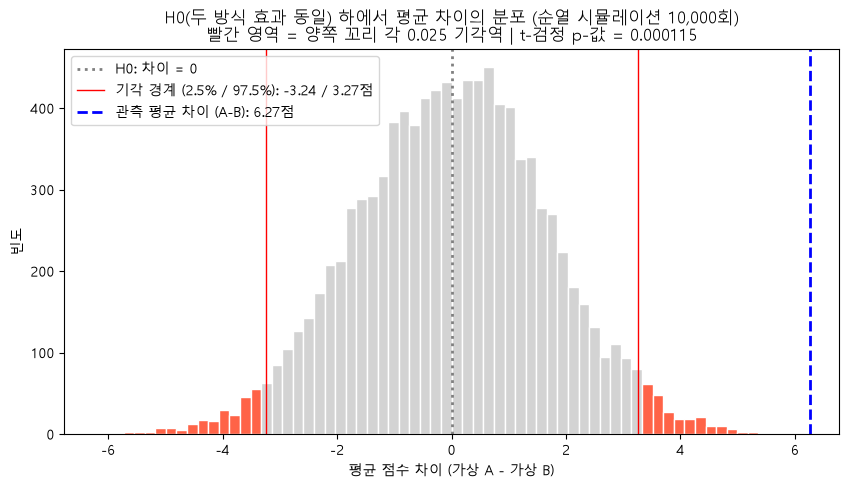

In [25]:
# [문제 3] Q5. 시뮬레이션으로 얻은 평균 차이의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 평균 차이(A그룹 평균 - B그룹 평균)를 세로선으로 함께 표시해 봅시다.

# 양측 기각 경계: 시뮬레이션 분포의 하위 2.5%, 상위 2.5% 지점
crit_low, crit_up = np.percentile(sim_diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hist(sim_diffs, bins=60, color='lightgray', edgecolor='white')

# 양쪽 꼬리(기각역) 막대 색칠
for patch, left, right in zip(patches, edges[:-1], edges[1:]):
    center = (left + right) / 2
    if center <= crit_low or center >= crit_up:
        patch.set_facecolor('tomato')

plt.axvline(0, color='gray', linestyle=':', linewidth=2, label='H0: 차이 = 0')
plt.axvline(crit_low, color='red', linestyle='-', linewidth=1,
            label=f'기각 경계 (2.5% / 97.5%): {crit_low:.2f} / {crit_up:.2f}점')
plt.axvline(crit_up, color='red', linestyle='-', linewidth=1)
plt.axvline(obs_diff, color='blue', linestyle='--', linewidth=2,
            label=f'관측 평균 차이 (A-B): {obs_diff:.2f}점')

# 관측값이 분포 밖에 있어도 보이도록 x축 범위 확장
plt.xlim(min(sim_diffs.min(), -abs(obs_diff)) - 0.5, max(sim_diffs.max(), abs(obs_diff)) + 0.5)

plt.title(f"H0(두 방식 효과 동일) 하에서 평균 차이의 분포 (순열 시뮬레이션 {n_sim:,}회)\n"
          f"빨간 영역 = 양쪽 꼬리 각 0.025 기각역 | t-검정 p-값 = {p_value:.6f}")
plt.xlabel("평균 점수 차이 (가상 A - 가상 B)")
plt.ylabel("빈도")
plt.legend(loc='upper left')
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?

- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

In [26]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 1. 두 검정 모두 H0가 '가정을 만족한다'이므로 p-값이 커야(≥ 0.05) 가정을 만족한다.
#    - 정규성: A(p=0.877), B(p=0.837) → 둘 다 정규성 만족
#    - 등분산성: p=0.015 < 0.05 → 등분산성 위배 (표준편차 A 9.10 vs B 6.13)
#    → t-검정은 쓸 수 있지만, 분산이 같다고 가정하는 Student's t-검정 대신
#      equal_var=False인 Welch's t-검정을 써야 한다.
#
# 2. H0(효과 동일)에서는 A/B 라벨이 의미 없으므로, 무작위로 섞어 나누면
#    어떤 때는 A가, 어떤 때는 B가 조금 높게 나와 평균적으로 차이가 0에 수렴하기 때문이다.
#
# 3. 벗어난다. 우연으로 생길 수 있는 차이는 대략 ±3.3점(기각 경계), 최대 ±5.7점인데
#    관측 차이 6.27점은 10,000번 시뮬레이션에서 한 번도 나오지 않았다.
#
# 4. p-값은 세로선보다 바깥쪽(양쪽 꼬리)의 넓이다. 세로선이 분포 밖에 있어서 넓이가 거의 0이고,
#    이것이 Q3의 매우 작은 p-값(0.000115)과 일치한다.
#
# 5. 방식 A가 평균 약 6점 더 높으므로 A를 주력 학습 방식으로 채택하거나 B를 A 방식으로 개선할 수 있다.
#    다만 A는 점수 편차가 더 커서(분산이 큼) 학생에 따라 효과가 들쭉날쭉할 수 있으니,
#    성적이 낮은 학생에게는 보충 지원을 함께 고려하는 게 좋다.

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
     액션  로맨스
20대  70   30
30대  50   60
40대  30   60


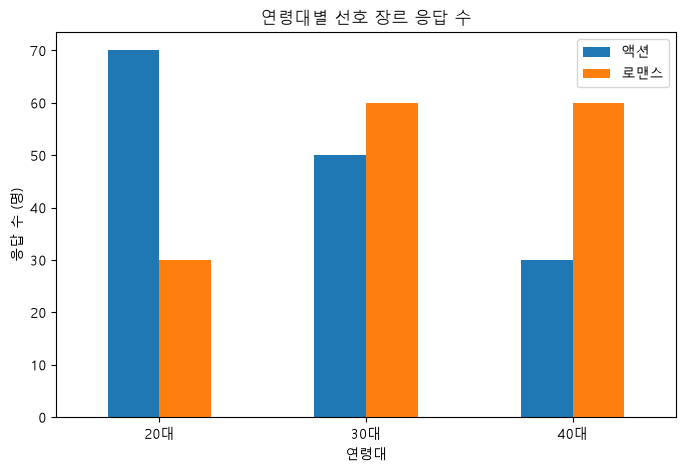

In [27]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [ ]:
# [문제 4] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 연령대와 선호 장르가 독립이다.
# H₁ (대립가설): 연령대와 선호 장르는 독립이 아니다.

In [28]:
# [문제 4] Q2. 카이제곱 독립성 검정을 수행하고 카이제곱 통계량, p-값, 자유도, 기대 빈도를 구해봅시다.
# 기대 빈도는 관측 빈도와 비교하기 쉽도록 데이터프레임 형태로 출력해보세요.

alpha = 0.05

chi2_stat, p_value, dof, expected = stats.chi2_contingency(observed)

print(f"카이제곱 통계량: {chi2_stat:.4f}")
print(f"p-값: {p_value:.8f}")
print(f"자유도: {dof}  (= (행 3 - 1) × (열 2 - 1))")

expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
print("\n기대 빈도 (Expected Frequencies):")
print(expected_df.round(2))

print("\n관측 - 기대 (차이):")
print((observed - expected_df).round(2))

if p_value < alpha:
    print("\n→ H0 기각: 연령대와 선호 장르는 서로 연관이 있다.")
else:
    print("\n→ H0 기각 실패: 연령대와 선호 장르가 연관이 있다고 보기 어렵다.")

카이제곱 통계량: 26.9091
p-값: 0.00000143
자유도: 2  (= (행 3 - 1) × (열 2 - 1))

기대 빈도 (Expected Frequencies):
       액션   로맨스
20대  50.0  50.0
30대  55.0  55.0
40대  45.0  45.0

관측 - 기대 (차이):
       액션   로맨스
20대  20.0 -20.0
30대  -5.0   5.0
40대 -15.0  15.0

→ H0 기각: 연령대와 선호 장르는 서로 연관이 있다.


In [30]:

# [문제 4] Q3. H₀가 사실(두 변수가 독립)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.

np.random.seed(0)
n_sim = 5000
total = observed.values.sum()                       # 300명

ages = observed.index.tolist()                      # ['20대', '30대', '40대']
genres = observed.columns.tolist()                  # ['액션', '로맨스']
age_prob = observed.sum(axis=1) / total             # 연령대 비율 (행 합 / 전체)
genre_prob = observed.sum(axis=0) / total           # 장르 비율 (열 합 / 전체)

sim_chi2 = []
for _ in range(n_sim):
    # H0(독립): 연령대와 장르를 '서로 따로' 무작위 할당
    fake_ages = np.random.choice(ages, size=total, p=age_prob)
    fake_genres = np.random.choice(genres, size=total, p=genre_prob)

    # 가상 분할표 (혹시 빠진 범주가 있으면 0으로 채움)
    fake_table = pd.crosstab(fake_ages, fake_genres).reindex(index=ages, columns=genres, fill_value=0)
    sim_chi2.append(stats.chi2_contingency(fake_table)[0])

sim_chi2 = np.array(sim_chi2)

print(f"시뮬레이션 카이제곱 통계량 평균: {sim_chi2.mean():.3f} (이론값 = 자유도 {dof})")
print(f"시뮬레이션 카이제곱 통계량 최댓값: {sim_chi2.max():.2f}")
print(f"관측 카이제곱 통계량: {chi2_stat:.2f}")

# 카이제곱 검정은 오른쪽 꼬리만 봄 (통계량이 클수록 독립에서 멀어짐)
n_extreme = np.sum(sim_chi2 >= chi2_stat)
if n_extreme == 0:
    print(f"시뮬레이션 p-값: < {1/n_sim} ({n_sim:,}번 중 한 번도 나오지 않음)")
else:
    print(f"시뮬레이션 p-값: {n_extreme / n_sim:.4f}")


시뮬레이션 카이제곱 통계량 평균: 2.042 (이론값 = 자유도 2)
시뮬레이션 카이제곱 통계량 최댓값: 19.10
관측 카이제곱 통계량: 26.91
시뮬레이션 p-값: < 0.0002 (5,000번 중 한 번도 나오지 않음)


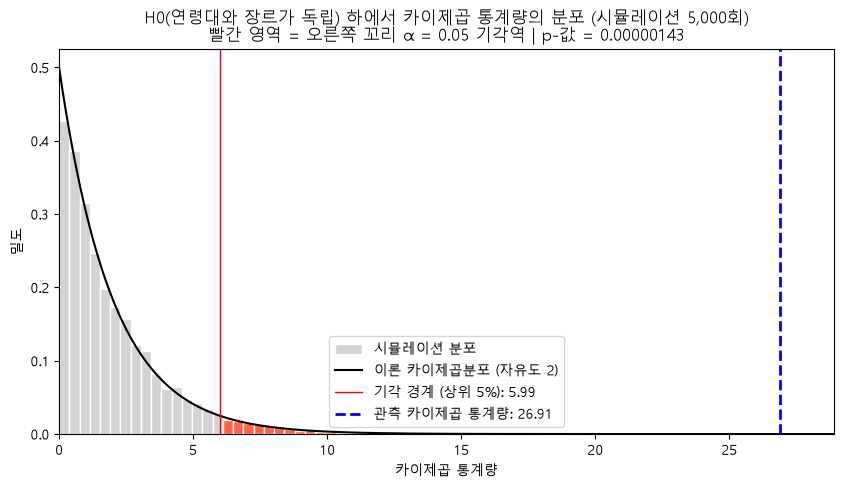

In [31]:
# [문제 4] Q4. 시뮬레이션으로 얻은 카이제곱 통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 카이제곱 통계량을 세로선으로 함께 표시해 봅시다.

# 카이제곱 검정은 오른쪽 꼬리만 사용: 상위 5% 지점이 기각 경계
chi2_crit = stats.chi2.ppf(1 - alpha, dof)

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hist(sim_chi2, bins=50, density=True, color='lightgray', edgecolor='white',
                                  label='시뮬레이션 분포')

# 오른쪽 꼬리(기각역) 막대 색칠
for patch, left, right in zip(patches, edges[:-1], edges[1:]):
    if (left + right) / 2 >= chi2_crit:
        patch.set_facecolor('tomato')

# 이론 카이제곱분포 곡선 겹쳐 그리기
x_line = np.linspace(0, max(sim_chi2.max(), chi2_stat) + 2, 300)
plt.plot(x_line, stats.chi2.pdf(x_line, dof), color='black', linewidth=1.5,
         label=f'이론 카이제곱분포 (자유도 {dof})')

plt.axvline(chi2_crit, color='red', linestyle='-', linewidth=1,
            label=f'기각 경계 (상위 5%): {chi2_crit:.2f}')
plt.axvline(chi2_stat, color='blue', linestyle='--', linewidth=2,
            label=f'관측 카이제곱 통계량: {chi2_stat:.2f}')

# 관측값이 분포 밖에 있어도 보이도록 x축 범위 확장
plt.xlim(0, max(sim_chi2.max(), chi2_stat) + 2)

plt.title(f"H0(연령대와 장르가 독립) 하에서 카이제곱 통계량의 분포 (시뮬레이션 {n_sim:,}회)\n"
          f"빨간 영역 = 오른쪽 꼬리 α = 0.05 기각역 | p-값 = {p_value:.8f}")
plt.xlabel("카이제곱 통계량")
plt.ylabel("밀도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?

- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?

- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?

In [32]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 1. 기대 빈도는 '연령대와 장르가 독립이라면' 각 칸에 있어야 할 인원수로, (행 합 × 열 합) / 전체로 구한다.
#    카이제곱 통계량 = Σ (관측 - 기대)² / 기대 이므로, 관측과 기대의 차이가 클수록 통계량이 커진다.
#
# 2. H0(독립)가 사실일 때 나올 수 있는 카이제곱 통계량의 분포(자유도 2인 카이제곱분포)다.
#    관측값 26.91은 기각 경계(5.99)를 훨씬 넘고, 시뮬레이션 최댓값(19.10)보다도 커서 매우 극단적인 값이다.
#
# 3. 있다. p-값(약 0.0000014)이 0.05보다 훨씬 작아 H0(독립)를 기각한다.
#    즉, 연령대에 따라 선호 장르가 다르다는 통계적 근거가 있다.
#
# 4. 20대는 액션 선호(기대보다 +20명), 30·40대는 로맨스 선호(+5명, +15명)가 뚜렷하다.
#    - 20대: 액션 영화 위주 상영, 대학가·저녁 시간대 액션 할인 프로모션
#    - 40대: 로맨스 영화 위주 상영, 주말 낮 시간대 커플·부부 패키지
#    - 연령대별 맞춤 추천·쿠폰 발송 (단, 연관성이 있다는 것이지 '나이가 원인'이라는 뜻은 아님에 주의)

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

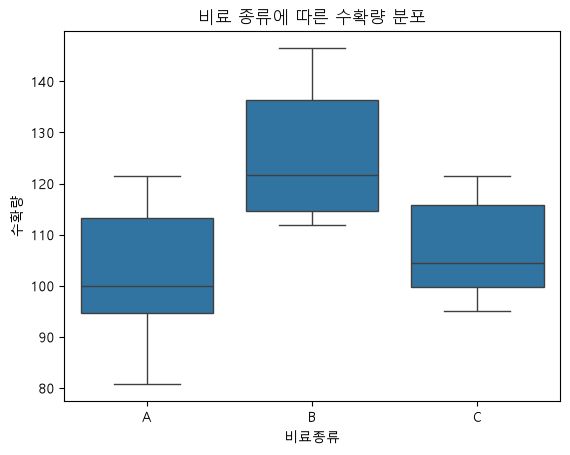

In [33]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

In [35]:
# [문제 5] Q1. 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.

alpha = 0.05

# 비료별 기술통계
print("비료별 수확량 요약:")
print(df.groupby('비료종류')['수확량'].agg(['mean', 'std', 'count']).round(2))

# 일원분산분석 (One-way ANOVA)
f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

k = df['비료종류'].nunique()   # 그룹 수 3
N = len(df)                    # 전체 표본 수 30
print(f"\nF-통계량: {f_stat:.4f}  (자유도: 그룹 간 {k - 1}, 그룹 내 {N - k})")
print(f"p-값: {p_value:.6f}")

if p_value < alpha:
    print("→ H0 기각: 적어도 하나의 비료는 평균 수확량이 다르다.")
else:
    print("→ H0 기각 실패: 세 비료의 평균 수확량이 다르다고 보기 어렵다.")

비료별 수확량 요약:
        mean    std  count
비료종류                      
A     102.30  13.03     10
B     125.98  13.75     10
C     107.15   9.74     10

F-통계량: 10.3455  (자유도: 그룹 간 2, 그룹 내 27)
p-값: 0.000462
→ H0 기각: 적어도 하나의 비료는 평균 수확량이 다르다.


In [36]:
# [문제 5] Q2. ANOVA의 p-값이 유의수준 0.05보다 작을 경우에만
# Tukey's HSD 사후분석을 수행하고 결과를 출력해봅시다.
# 힌트: pairwise_tukeyhsd(endog=수확량, groups=비료종류, alpha=0.05)

alpha = 0.05

if p_value < alpha:
    print("→ H0 기각: 적어도 하나의 비료 평균이 다르다. Tukey's HSD 사후분석을 수행합니다.\n")
    tukey = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=alpha)
    print(tukey)

    # 그룹별 평균도 함께 확인
    print("\n비료별 평균 수확량:")
    print(df.groupby('비료종류')['수확량'].mean().round(2))
else:
    print("→ H0 기각 실패: 세 비료의 평균 차이가 유의미하지 않으므로 사후분석을 하지 않습니다.")

→ H0 기각: 적어도 하나의 비료 평균이 다르다. Tukey's HSD 사후분석을 수행합니다.

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------

비료별 평균 수확량:
비료종류
A    102.30
B    125.98
C    107.15
Name: 수확량, dtype: float64


In [38]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

np.random.seed(0)
n_sim = 5000
n_group = 10

# H0 모집단: 세 비료 구분 없이 전체 데이터의 평균·표준편차
all_yield = df['수확량'].values
h0_mean = all_yield.mean()
h0_std = all_yield.std(ddof=1)
print(f"H0 모집단: 평균 {h0_mean:.2f}, 표준편차 {h0_std:.2f}")

sim_f = []
for _ in range(n_sim):
    # 같은 모집단에서 10개씩 3개 그룹 생성 → 평균 차이는 순전히 우연
    fake_a = np.random.normal(h0_mean, h0_std, n_group)
    fake_b = np.random.normal(h0_mean, h0_std, n_group)
    fake_c = np.random.normal(h0_mean, h0_std, n_group)
    sim_f.append(stats.f_oneway(fake_a, fake_b, fake_c)[0])

sim_f = np.array(sim_f)

print(f"시뮬레이션 F-통계량 평균: {sim_f.mean():.3f}  (H0이면 1 근처)")
print(f"시뮬레이션 F-통계량 최댓값: {sim_f.max():.2f}")
print(f"관측 F-통계량: {f_stat:.2f}")

# F-검정은 오른쪽 꼬리만 봄 (F가 클수록 그룹 간 차이가 큼)
n_extreme = np.sum(sim_f >= f_stat)
if n_extreme == 0:
    print(f"시뮬레이션 p-값: < {1/n_sim} ({n_sim:,}번 중 한 번도 나오지 않음)")
else:
    print(f"시뮬레이션 p-값: {n_extreme / n_sim:.4f}  ({n_sim:,}번 중 {n_extreme}번)")

H0 모집단: 평균 111.81, 표준편차 15.77
시뮬레이션 F-통계량 평균: 1.030  (H0이면 1 근처)
시뮬레이션 F-통계량 최댓값: 11.96
관측 F-통계량: 10.35
시뮬레이션 p-값: 0.0004  (5,000번 중 2번)


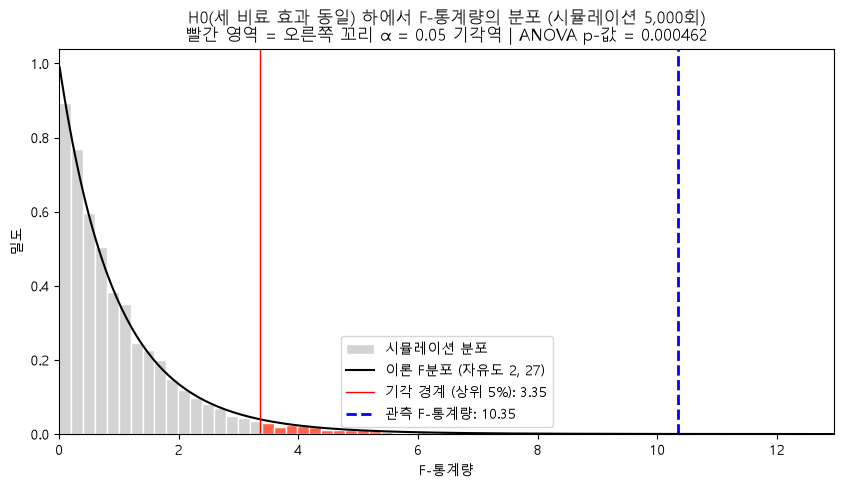

In [39]:
# [문제 5] Q4. 시뮬레이션으로 얻은 F-통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 F-통계량을 세로선으로 함께 표시해 봅시다.

# F-검정은 오른쪽 꼬리만 사용: 상위 5% 지점이 기각 경계
df_between, df_within = k - 1, N - k          # 자유도 (2, 27)
f_crit = stats.f.ppf(1 - alpha, df_between, df_within)
x_max = max(sim_f.max(), f_stat) + 1

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hist(sim_f, bins=60, density=True, color='lightgray', edgecolor='white',
                                  label='시뮬레이션 분포')

# 오른쪽 꼬리(기각역) 막대 색칠
for patch, left, right in zip(patches, edges[:-1], edges[1:]):
    if (left + right) / 2 >= f_crit:
        patch.set_facecolor('tomato')

# 이론 F분포 곡선 겹쳐 그리기
x_line = np.linspace(0.01, x_max, 300)
plt.plot(x_line, stats.f.pdf(x_line, df_between, df_within), color='black', linewidth=1.5,
         label=f'이론 F분포 (자유도 {df_between}, {df_within})')

plt.axvline(f_crit, color='red', linestyle='-', linewidth=1,
            label=f'기각 경계 (상위 5%): {f_crit:.2f}')
plt.axvline(f_stat, color='blue', linestyle='--', linewidth=2,
            label=f'관측 F-통계량: {f_stat:.2f}')

plt.xlim(0, x_max)
plt.title(f"H0(세 비료 효과 동일) 하에서 F-통계량의 분포 (시뮬레이션 {n_sim:,}회)\n"
          f"빨간 영역 = 오른쪽 꼬리 α = 0.05 기각역 | ANOVA p-값 = {p_value:.6f}")
plt.xlabel("F-통계량")
plt.ylabel("밀도")
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q5. 분석 결과를 바탕으로 연구소에 어떤 비료를 추천하시겠습니까?
# 추천: 비료 B
#
# 근거
# 1. ANOVA(F = 10.35, p = 0.00046)로 세 비료의 평균 수확량이 모두 같지는 않다는 것을 확인했다.
# 2. Tukey's HSD 결과, B는 A보다 약 23.7, C보다 약 18.8 더 많이 수확되며 두 차이 모두 유의미하다.
#    (A-B, B-C 모두 reject = True, 신뢰구간이 0을 포함하지 않음)
# 3. 평균 수확량이 B 125.98 > C 107.15 > A 102.30으로 B가 가장 높고,
#    B의 최저 수확량(111.9)조차 A·C의 평균보다 높다.
# 4. A와 C는 유의미한 차이가 없으므로(p = 0.657), B를 쓸 수 없다면 둘 중 가격이 싸거나 구하기 쉬운 쪽을 고르면 된다.
#
# 주의할 점
# - 그룹당 표본이 10개로 적어 추정이 불안정할 수 있으므로, 실제 도입 전에 더 많은 밭에서 재검증하는 것이 좋다.
# - 수확량만 비교했으므로 비료 가격, 토양·환경 영향, 작물 품질 등도 함께 고려해야 한다.


**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?

- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?

- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?

- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?

In [40]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 1. p-값(0.00046) < 0.05이므로 H0를 기각한다.
#    이는 "적어도 하나의 비료는 평균이 다르다"는 뜻이지, 어느 비료가 다른지나 모두 다르다는 뜻은 아니다.
#    그래서 어떤 쌍이 다른지는 사후분석으로 따로 확인해야 한다.
#
# 2. A-B, B-C 조합이 True다. 두 비료의 평균 수확량이 통계적으로 유의미하게 다르다는 뜻이다.
#    A-C는 False로, 두 비료의 차이는 우연으로 볼 수 있는 수준이다.
#
# 3. meandiff는 두 그룹의 평균 차이(group2 - group1)로, 차이의 크기와 방향을 보여준다.
#    신뢰구간이 0을 포함하면 '차이가 0일 수도 있다' → 유의미하지 않음 (A-C: -8.79 ~ 18.48)
#    0을 포함하지 않으면 유의미한 차이다. (A-B: 10.04 ~ 37.31, B-C: -32.47 ~ -5.20)
#
# 4. 표본이 작으면 표준오차가 커져서 신뢰구간이 넓어지고, 실제 차이가 있어도 찾아내지 못할 수 있다(검정력 저하).
#    또 이상치 하나에 결과가 크게 흔들린다.
#    → 밭 수를 늘리고, 여러 지역·시즌에 걸쳐 반복 실험하면 결론의 신뢰도를 높일 수 있다.